<a href="https://colab.research.google.com/github/Martazzz/student_performance_project/blob/main/notebooks/01_cleaning_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **01 - Data cleaning and EDA**
---
Predict Students' Dropout and Academic Success project. Phase 0 (data preparation) and phase 1 (EDA).

## Style and palette
---
Common style for the whole project. The `ORDER` dictionary and the `apply_order` function make every chart show the categories in a logical order (Low, Medium, High) instead of the alphabetical one.

In [1]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams.update(
    {
        "figure.figsize": (9, 5),
        "axes.titlesize": 14,
        "axes.titleweight": "bold",
        "axes.labelsize": 12,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
    }
)

OUTCOME_ORDER = ["Dropout", "Enrolled", "Graduate"]
OUTCOME_PALETTE = {"Dropout": "#E69F00", "Enrolled": "#9E9E9E", "Graduate": "#0072B2"}
BAR_COLOR = "#0072B2"
DROPOUT_COLOR = "#E69F00"

os.makedirs("figures", exist_ok=True)

ORDER = {
    "Target": OUTCOME_ORDER,
    "Gender": ["Female", "Male"],
    "Displaced": ["No", "Yes"],
    "Debtor": ["No", "Yes"],
    "Tuition_Up_To_Date": ["No", "Yes"],
    "Scholarship_Holder": ["No", "Yes"],
    "Daytime_Evening": ["Daytime", "Evening"],
    "Marital_Group": ["Single", "Not single"],
    "Age_Group": ["17-19", "20-24", "25-29", "30+"],
    "Admission_Grade_Band": ["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"],
    "Parent_Education": ["Basic", "Secondary", "Higher", "Unknown"],
    "Application_Order_Group": ["0-1", "2", "3+"],
    "Application_Mode_Group": [
        "General contingent",
        "Over 23 years old",
        "Transfer or change",
        "Prior diploma holder",
        "Special or other",
    ],
    "Passed_None_1st": ["No", "Yes"],
    "Passed_None_2nd": ["No", "Yes"],
}


def apply_order(df):
    df = df.copy()
    for col, cats in ORDER.items():
        if col in df.columns:
            df[col] = pd.Categorical(df[col], categories=cats, ordered=True)
    return df

## Reading data
---
We load the data, choose the columns to keep and rename them. From 37 columns we decided to keep only 22 of them for our analysis.

In [4]:
raw = pd.read_csv("data.csv", sep=";", encoding="utf-8-sig")

raw.columns = raw.columns.str.strip()
print(raw.shape)

RENAME = {
    "Marital status": "Marital_Status",
    "Application mode": "Application_Mode",
    "Application order": "Application_Order",
    "Course": "Course",
    "Daytime/evening attendance": "Daytime_Evening",
    "Previous qualification (grade)": "Prev_Qual_Grade",
    "Mother's qualification": "Mother_Qualification",
    "Father's qualification": "Father_Qualification",
    "Admission grade": "Admission_Grade",
    "Displaced": "Displaced",
    "Debtor": "Debtor",
    "Tuition fees up to date": "Tuition_Up_To_Date",
    "Gender": "Gender",
    "Scholarship holder": "Scholarship_Holder",
    "Age at enrollment": "Age_At_Enrollment",
    "Curricular units 1st sem (enrolled)": "Enrolled_1st",
    "Curricular units 1st sem (approved)": "Approved_1st",
    "Curricular units 1st sem (grade)": "Grade_1st",
    "Curricular units 2nd sem (enrolled)": "Enrolled_2nd",
    "Curricular units 2nd sem (approved)": "Approved_2nd",
    "Curricular units 2nd sem (grade)": "Grade_2nd",
    "Target": "Target",
}

data = raw[list(RENAME)].rename(columns=RENAME).copy()
print(f"{data.shape[0]} rows, {data.shape[1]} columns")

(4424, 37)
4424 rows, 22 columns


## Look at the data and mapping
---
We look at the data to spot missing values, duplicated rows and the distribution of the target. Then we map the indexes of courses name and application mode because in the data they are represented by a number.

In [6]:
data.info()
print("Missing values:", data.isna().sum().sum())
print("Duplicated rows:", data.duplicated().sum())
print(data["Target"].value_counts())

COURSE_NAMES = {
    33: "Biofuel Production Technologies",
    171: "Animation and Multimedia Design",
    8014: "Social Service (evening)",
    9003: "Agronomy",
    9070: "Communication Design",
    9085: "Veterinary Nursing",
    9119: "Informatics Engineering",
    9130: "Equinculture",
    9147: "Management",
    9238: "Social Service",
    9254: "Tourism",
    9500: "Nursing",
    9556: "Oral Hygiene",
    9670: "Advertising and Marketing Management",
    9773: "Journalism and Communication",
    9853: "Basic Education",
    9991: "Management (evening)",
}

APPLICATION_MODE_GROUPS = {
    1: "General contingent",
    17: "General contingent",
    18: "General contingent",
    39: "Over 23 years old",
    42: "Transfer or change",
    43: "Transfer or change",
    51: "Transfer or change",
    57: "Transfer or change",
    7: "Prior diploma holder",
    44: "Prior diploma holder",
    53: "Prior diploma holder",
    2: "Special or other",
    5: "Special or other",
    10: "Special or other",
    15: "Special or other",
    16: "Special or other",
    26: "Special or other",
    27: "Special or other",
}

EDUCATION_LEVEL = {}
for code in [11, 19, 26, 27, 29, 30, 35, 36, 37, 38]:
    EDUCATION_LEVEL[code] = "Basic"
for code in [1, 9, 10, 12, 13, 14, 18, 20, 22, 25, 31, 33, 39]:
    EDUCATION_LEVEL[code] = "Secondary"
for code in [2, 3, 4, 5, 6, 40, 41, 42, 43, 44]:
    EDUCATION_LEVEL[code] = "Higher"
EDUCATION_LEVEL[34] = "Unknown"

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Marital_Status        4424 non-null   int64  
 1   Application_Mode      4424 non-null   int64  
 2   Application_Order     4424 non-null   int64  
 3   Course                4424 non-null   int64  
 4   Daytime_Evening       4424 non-null   int64  
 5   Prev_Qual_Grade       4424 non-null   float64
 6   Mother_Qualification  4424 non-null   int64  
 7   Father_Qualification  4424 non-null   int64  
 8   Admission_Grade       4424 non-null   float64
 9   Displaced             4424 non-null   int64  
 10  Debtor                4424 non-null   int64  
 11  Tuition_Up_To_Date    4424 non-null   int64  
 12  Gender                4424 non-null   int64  
 13  Scholarship_Holder    4424 non-null   int64  
 14  Age_At_Enrollment     4424 non-null   int64  
 15  Enrolled_1st         

## Cleaning data
---
**Missing values.** We search for null values and substitute them with the mode of the variable.

In [ ]:
missing = data.isna().sum()
print("Null values per column:")
print(missing[missing > 0])

for c in ["Teacher_Quality", "Distance_from_Home"]:
    data[c] = data[c].fillna(data[c].mode()[0])

print("\nRemaining missing values in dataset:", data.isna().sum().sum())

Null values per column:
Teacher_Quality       78
Distance_from_Home    67
dtype: int64

Remaining missing values in dataset: 0


---
**Anomalies** The exam score must be between 0 and 100, the attendance too.
We remove the rows that violate this rule and we count how many rows are removed.

In [ ]:
n_before = len(data)
data = data[data["Exam_Score"].between(0, 100) & data["Attendance"].between(0, 100)]
removed = n_before - len(data)
print(f"Removed {removed} rows")

Removed 1 rows


## Numerical representation of the categories
---
We assign to each category a numerical representation (used later for correlations, clustering and models):

- No:0, Yes:1
- Public:0, Private:1
- Female:0, Male:1
- Low:0, Medium:1, High:2
- Negative:0, Neutral:1, Positive:2
- Near:0, Moderate:1, Far:2

In [ ]:
data["Extracurricular_Activities_num"] = data["Extracurricular_Activities"].map({"No": 0, "Yes": 1})
data["School_Type_num"] = data["School_Type"].map({"Public": 0, "Private": 1})
data["Learning_Disabilities_num"] = data["Learning_Disabilities"].map({"No": 0, "Yes": 1})
data["Gender_num"] = data["Gender"].map({"Female": 0, "Male": 1})

mapping_levels_3 = {"Low": 0, "Medium": 1, "High": 2}
mapping_peer = {"Negative": 0, "Neutral": 1, "Positive": 2}
mapping_distance = {"Near": 0, "Moderate": 1, "Far": 2}

data["Parental_Involvement_num"] = data["Parental_Involvement"].map(mapping_levels_3)
data["Motivation_Level_num"] = data["Motivation_Level"].map(mapping_levels_3)
data["Family_Income_num"] = data["Family_Income"].map(mapping_levels_3)
data["Teacher_Quality_num"] = data["Teacher_Quality"].map(mapping_levels_3)
data["Peer_Influence_num"] = data["Peer_Influence"].map(mapping_peer)
data["Distance_from_Home_num"] = data["Distance_from_Home"].map(mapping_distance)

num_cols_check = [c for c in data.columns if c.endswith("_num")]
print("NaN in the numeric codes:", data[num_cols_check].isna().sum().sum())

NaN in the numeric codes: 0


## Derived variables
---
- `Score_Change`: difference between the new score and the previous one.
- `Hours_Studied_Bins`: hours studied split into 4 quartiles.
- `PrevScore_Band`: previous score split into 3 bands (low, medium, high), to compare students who started from the same level.
- `Tutoring_Group`: students with or without tutoring sessions.


In [ ]:
data["Score_Change"] = data["Exam_Score"] - data["Previous_Scores"]

data["Hours_Studied_Bins"] = pd.qcut(data["Hours_Studied"], q=4, labels=ORDER["Hours_Studied_Bins"])
data["PrevScore_Band"] = pd.qcut(data["Previous_Scores"], q=3, labels=ORDER["PrevScore_Band"])
data["Tutoring_Group"] = np.where(data["Tutoring_Sessions"] > 0, "With tutoring", "No tutoring")

print("Students per hours bin:")
print(data["Hours_Studied_Bins"].value_counts().reindex(ORDER["Hours_Studied_Bins"]))
print("\nReal range of each hours bin:")
print(data.groupby("Hours_Studied_Bins", observed=True)["Hours_Studied"].agg(["min", "max"]))

print("\nReal range of each previous-score band:")
print(data.groupby("PrevScore_Band", observed=True)["Previous_Scores"].agg(["min", "max", "count"]))

print("\nTutoring groups:")
print(data["Tutoring_Group"].value_counts())

Students per hours bin:
Hours_Studied_Bins
Low (Q1)            1856
Medium-Low (Q2)     1688
Medium-High (Q3)    1601
High (Q4)           1461
Name: count, dtype: int64

Real range of each hours bin:
                    min  max
Hours_Studied_Bins          
Low (Q1)              1   16
Medium-Low (Q2)      17   20
Medium-High (Q3)     21   24
High (Q4)            25   44

Real range of each previous-score band:
                min  max  count
PrevScore_Band                 
Low              50   67   2305
Medium           68   83   2110
High             84  100   2191

Tutoring groups:
Tutoring_Group
With tutoring    5093
No tutoring      1513
Name: count, dtype: int64


## Clean dataset

We apply the order of the categories and save the file. The saved CSV uses the **comma** as separator
and does not remember the order of the categories: in the other notebooks load it with
`pd.read_csv("student_performance_cleaned.csv")` and then call `data = apply_order(data)`.

In [ ]:
data = apply_order(data)
print(f"Final dataset: {data.shape[0]} rows, {data.shape[1]} columns")

file_name = "student_performance_cleaned.csv"
data.to_csv(file_name, index=False)

Final dataset: 6606 rows, 31 columns


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## **Type of data**

---
We slipt the data into two categories: the categorical data and the numerical data

In [ ]:
import os

os.makedirs("figures", exist_ok=True)

cat_cols = ["Gender", "School_Type", "Learning_Disabilities", "Extracurricular_Activities",
            "Parental_Involvement", "Motivation_Level", "Family_Income", "Teacher_Quality",
            "Peer_Influence", "Distance_from_Home"]

num_cols = ["Hours_Studied", "Attendance", "Sleep_Hours", "Previous_Scores",
            "Tutoring_Sessions", "Physical_Activity", "Exam_Score"]

# Categorical data count

For each categorical parameter we count the students and visualize the bar plots.

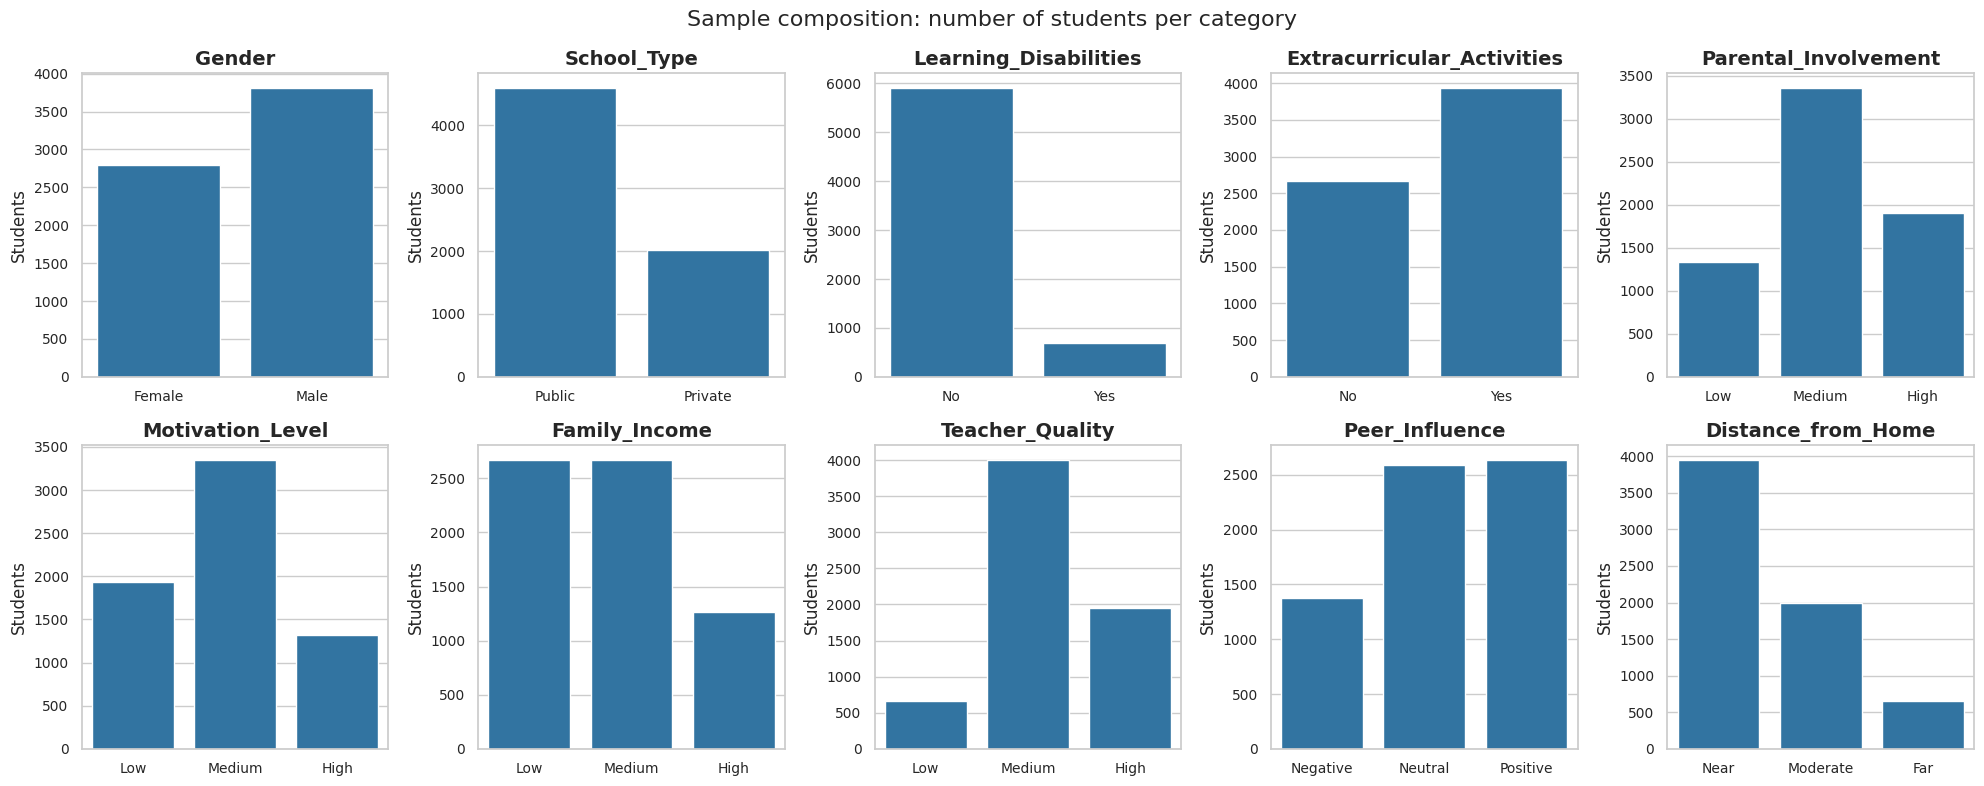

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8))

for ax, col in zip(axes.flat, cat_cols):
    sns.countplot(data=data, x=col, color=BAR_COLOR, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Students")

fig.suptitle("Sample composition: number of students per category", fontsize=16)
plt.tight_layout()
plt.savefig("figures/eda_categorical.png", dpi=200, bbox_inches="tight")
plt.show()

# Numerical data distribution

For each numerical parameter we visualize the distribution of its values

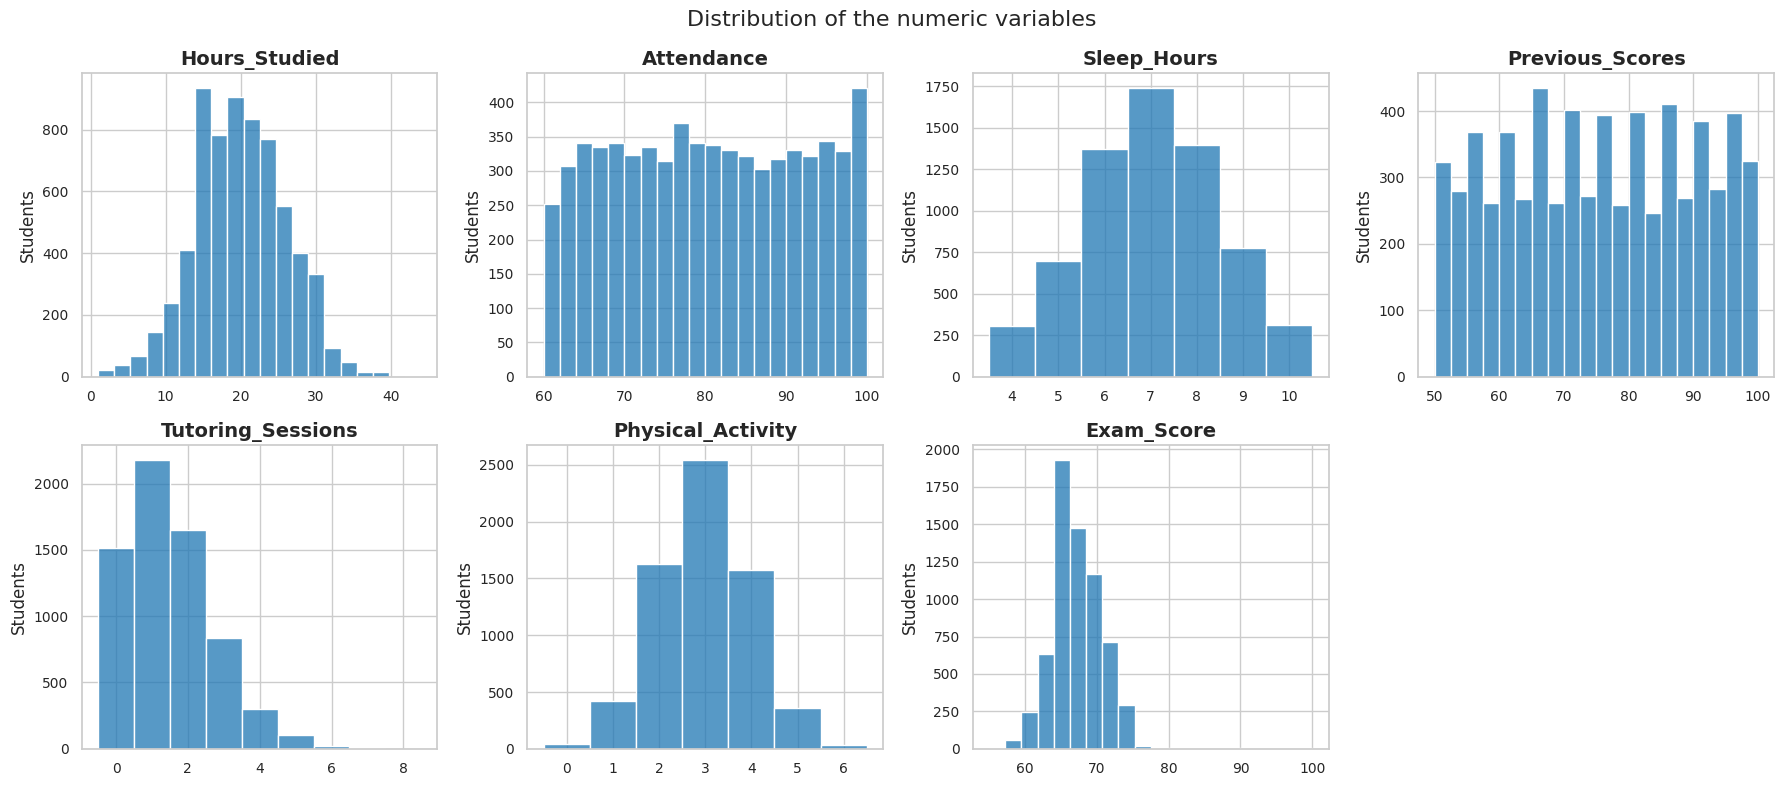

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for ax, col in zip(axes.flat, num_cols):
    if data[col].nunique() < 15:
        sns.histplot(data=data, x=col, discrete=True, color=BAR_COLOR, ax=ax)
    else:
        sns.histplot(data=data, x=col, bins=20, color=BAR_COLOR, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Students")

axes.flat[-1].axis("off")
fig.suptitle("Distribution of the numeric variables", fontsize=16)
plt.tight_layout()
plt.savefig("figures/eda_numeric.png", dpi=200, bbox_inches="tight")
plt.show()

# Data correlation

We consider the numerical parmeters and the numerical version of categorical parameters produced in the `Phase 0` of the project (for example Low, Medium and High became 0,1 and 2) and we see which parameters are correlated using a heatmap.



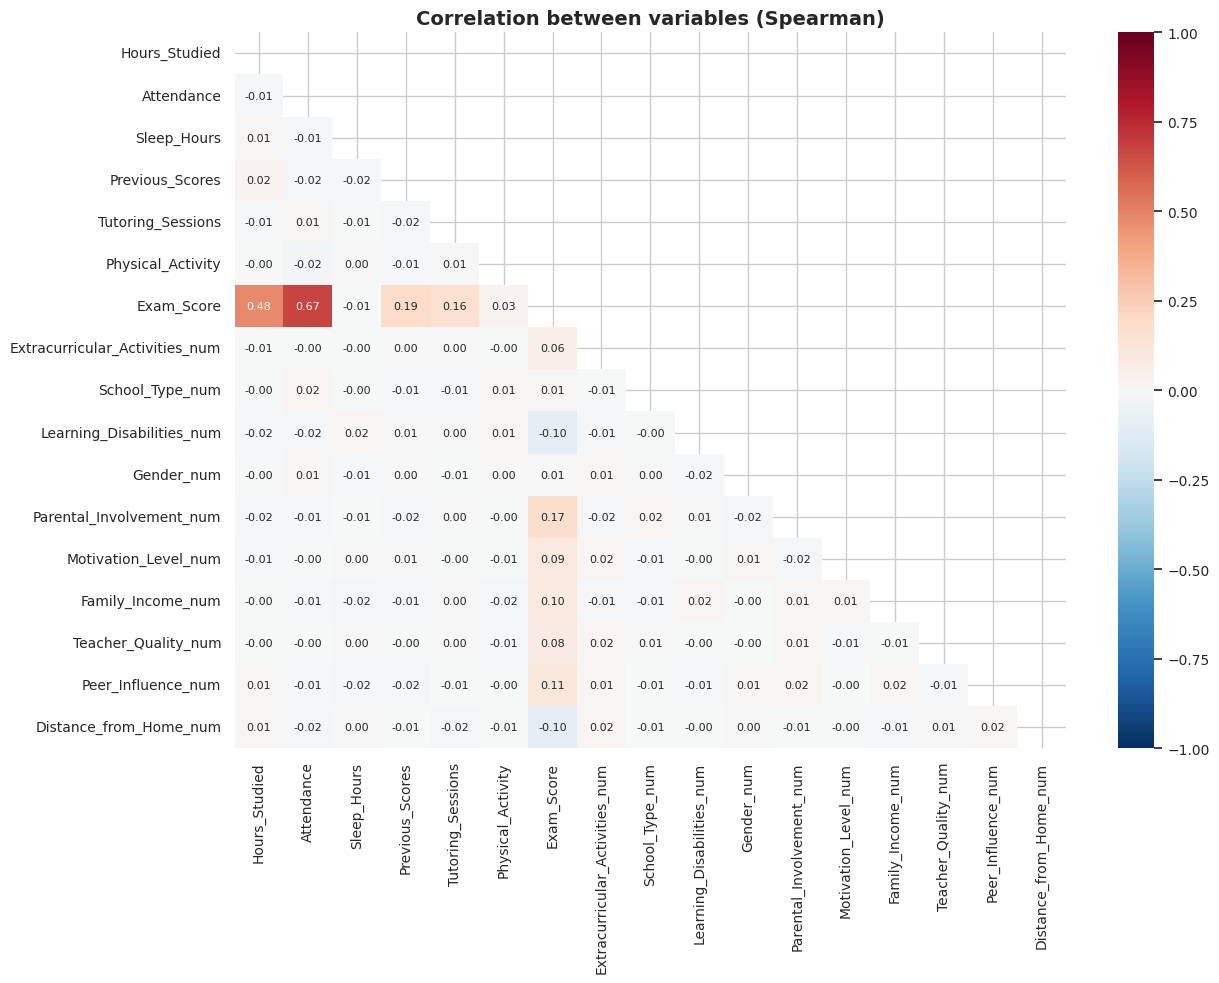

In [ ]:
num_codes = [c for c in data.columns if c.endswith("_num")]
corr_cols = num_cols + num_codes
corr = data[corr_cols].corr(method="spearman")

mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(13, 10))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, center=0, annot_kws={"size": 8})
plt.title("Correlation between variables (Spearman)")
plt.tight_layout()
plt.savefig("figures/eda_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

# Correlation with Exam Score

Considering only the correlation with the exam score, we plot the significant ones (positive and negative).

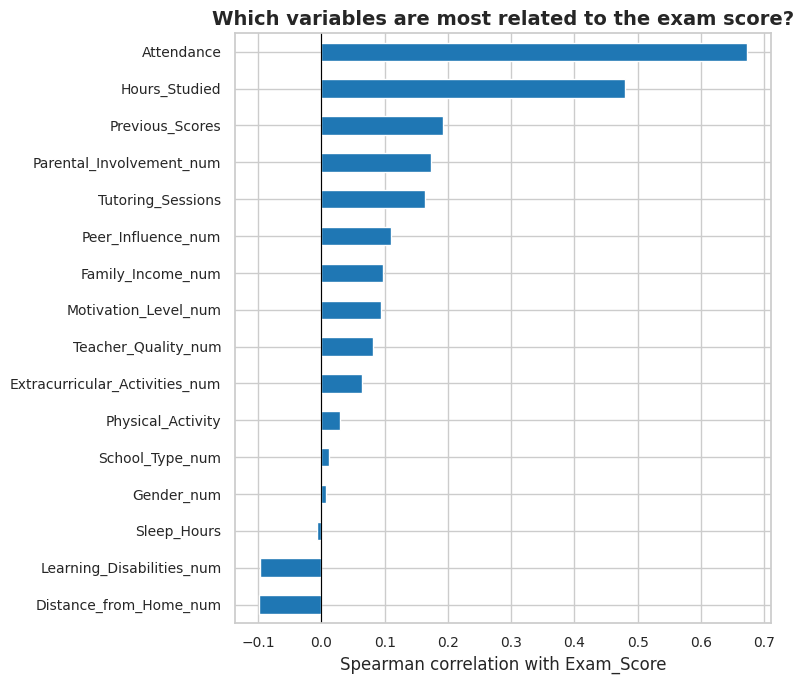

In [ ]:
corr_exam = corr["Exam_Score"].drop("Exam_Score").sort_values()

plt.figure(figsize=(8, 7))
corr_exam.plot(kind="barh", color=BAR_COLOR)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Spearman correlation with Exam_Score")
plt.title("Which variables are most related to the exam score?")
plt.tight_layout()
plt.savefig("figures/eda_corr_examscore.png", dpi=200, bbox_inches="tight")
plt.show()

# Mean score by category

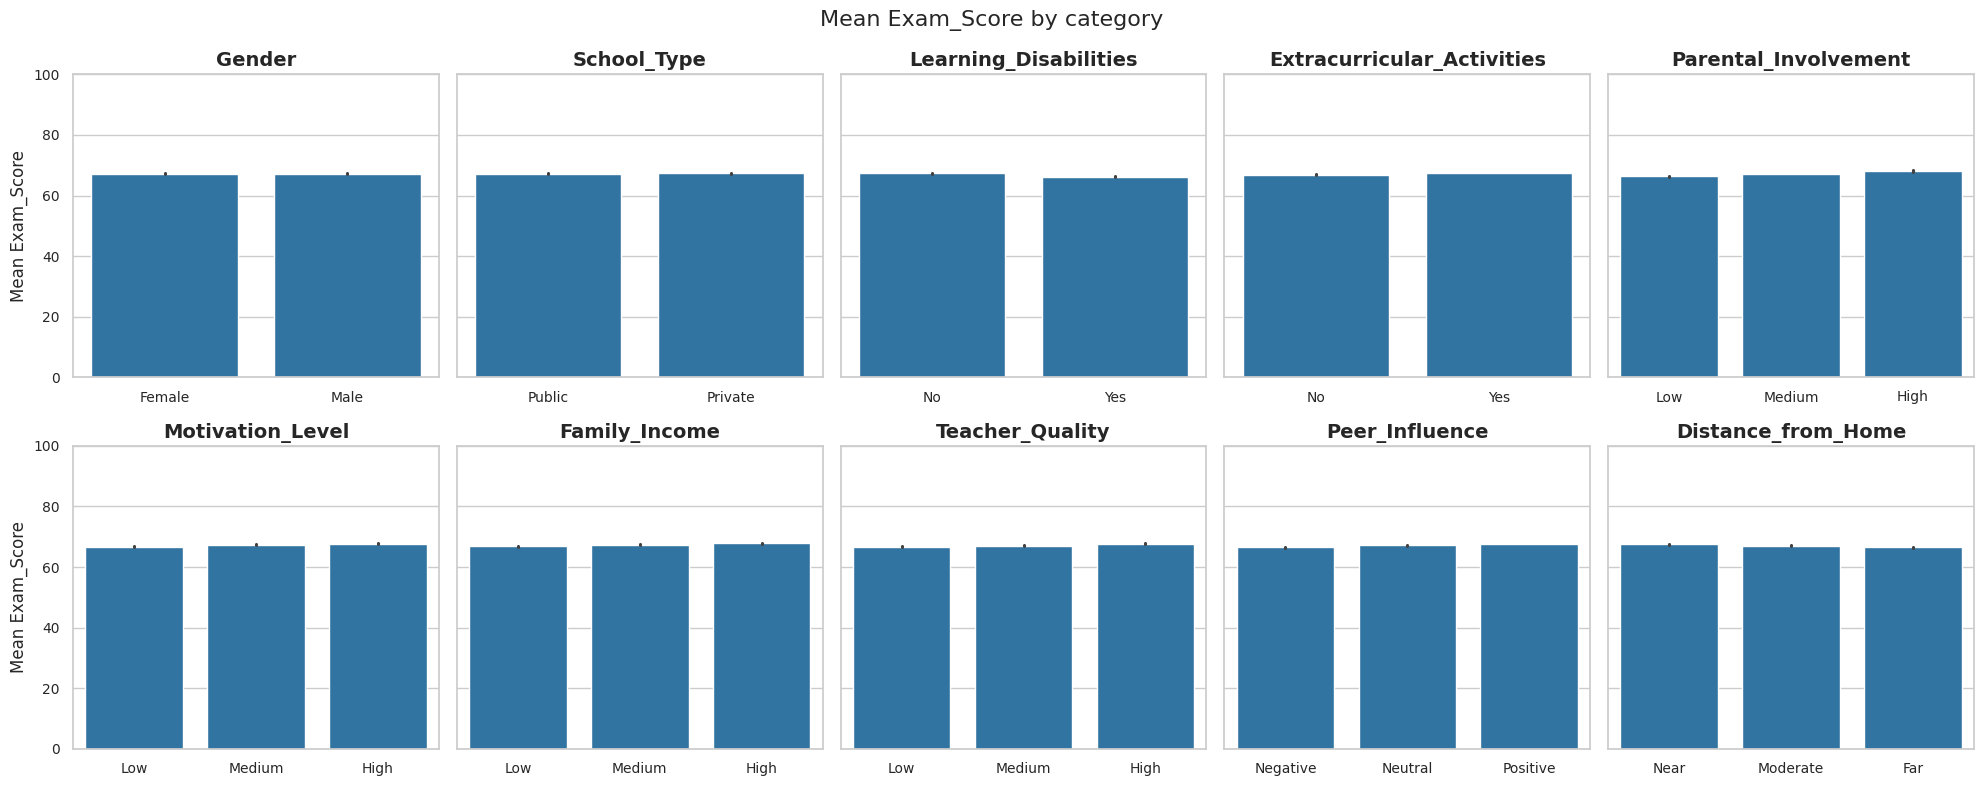

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8), sharey=True)

for ax, col in zip(axes.flat, cat_cols):
    sns.barplot(data=data, x=col, y="Exam_Score", color=BAR_COLOR, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Mean Exam_Score")
    ax.set_ylim(0, 100)

fig.suptitle("Mean Exam_Score by category", fontsize=16)
plt.tight_layout()
plt.savefig("figures/eda_examscore_by_category.png", dpi=200, bbox_inches="tight")
plt.show()